<center>

###### Signals & Systems
## Project - Phase 1
### Mahan Zamani(402101877) - Sina Hashemi(402102668)

## 1 Project Description and Theoretical Questions

### 1.1 Introduction to Singal Noise Cancelling

1. Conduct research on the introduced noise models and describe them in your own words. Provide an explanation of these models in the context of discrete-time signals, and formulate them within the discrete-time domain.

    - **Gaussian noise:** A Gaussian (normal) random noise has each sample drawn from a gaussian distribution. It is fully characterized by its mean and variance($ \mu $ and $ \sigma $).In discrete-time, each sample is an independent random variable drawn from a Gaussian distribution, $ x[n] \sim \mathcal{N}(0,\sigma^2) $.

    - **Uniform noise**: Uniform noise has samples equally likely over an interval $ [-A:A] $. This means all values within the range [-A, A] are equally likely to occur. The discrete-time version has each sample $x[n]$ uniformly distributed between $-A$ and $+A$, with mean = 0 and variance = $\frac{A^2}{3}$.

    - **White noise**: White noise is a sound that contains all frequencies within the range of human hearing. In practice, one generates white noise by drawing samples from any zero‐mean distribution (commonly Gaussian) that are uncorrelated, means that $ x[n] \sim \mathcal{N}(0,\sigma^2) uncorrelated $

    - **Impulse noise**: Impulse noise consists of short-duration, high-amplitude spikes that occur randomly. It's common in digital communication systems and can result from switching transients, lightning, or other sudden disturbances. Ih discrete-time, $x[n] = \delta[n]$ or in more genreal form $x[n] = \delta[n-n_0]$.

    - **Power line noise**: This noise stems from AC power sources (50 Hz for Iran). In discrete-time, it is a sampled sinusoid at the power line frequency. $ x[n] = A\sin(2\pi \frac{f}{F_s}n + \phi) $ with $f = 50 Hz$ and $ F_s $ the sampling rate.

---

2. Research the introduced noise-canceling methods and explain them in your own words. Make sure to formulate these methods using mathematical equations. Additionally, discuss the advantages and disadvantages of each method. (Note: You do not need to explain the Adaptive Filtering method in this question.)

    - **FIR filtering**: A Finite Impulse Response (FIR) filter uses a finite number of input samples to compute its output. It operates via convolution between the input signal and a set of filter coefficients.
    $$ y[n] = \sum^{N-1}_{k=0} h[k]x[n-k] $$
    where $h[n]$ are the filter coefficients and $N$ is the filter length.
    The transfer function in Z-domain is:
    $$ H(z) = \sum^{N-1}_{k=0} h[k]z^{-k} $$

    Advantages:

        - Guaranteed stability: All poles at the origin.
        - Linear Phase: Preserves signal timing relationships.
        - No feedback, so finite precision effects are minimal.
        - Design simplicity.

    Disadvantages:

        - Long filter lengths: Sharp cutoffs require large N, increasing latency & compute.
        - Fixed coefficients: Cannot adapt to time-varying noise.

    - **IIR filtering**: An Infinite Impulse Response (IIR) filter uses feedback, allowing its output to depend on both input and past output values. This recursive structure enables efficient frequency-selective filtering with fewer coefficients than FIR filters.
    $$ y[n] = \sum^{N}_{k=0} b_k x[n-k] - \sum^{M}_{k=1} a_k y[n-k] $$
    The transfer function in Z-domain is:
    $$ H(z) = \frac{\sum^{N}_{k=0} b_k z^{-k}}{1 + \sum^{M}_{k=1} a_k z^{-k}} = \frac{B(z)}{A(z)} $$

    Advantages:

        - Efficiency: Achieves sharp roll-offs (e.g., lowpass/highpass) with fewer taps than FIR.
        - Flexibility: Can model resonant or recursive systems.

    Disadvantages:

        - Nonlinear Phase: Feedback introduces phase distortion.
        - Potential Instability: Poorly chosen a[m] can place poles outside the unit circle.
        - Complex Design: Requires iterative methods for coefficient tuning.

### 1.2 Eigen Signals

1. Explain the concept of eigen signals in your own words. How are eigen signals used in signal processing? What are the advantages of using eigen signals?

Eigen signals (also called principal components) are simply the eigenvectors of a signal’s covariance matrix.
These signals are optimized to represent the underlying structure of a dataset with minimal redundancy, making them ideal for tasks like compression, feature extraction, and noise removal.
$$
    R = \mathcal{E}[xx^T], \qquad R u_k = \lambda_k u_k, \qquad k = 1, \dots N
$$
Each $u_k$ is an eigen signal of x. Thus,
$$
    x = \sum^N_{k=1} a_k u_k
$$

- Applications in Signal Processing

1. Transform Domain Processing: Because the eigen-signals diagonalize the covariance, the transform coefficients  are uncorrelated. So using eigen signals we can transform original signals into some coefficients and analyse them easier. For example Fourier Transform uses complex exponentials $e^{j2 \pi ft})$ as eigen signals.

2.  Image Compression: In JPEG compression, the DCT decomposes image blocks into frequency components and Most energy concentrates in low-frequency coefficients, allowing high compression ratios. Also by Keeping only the first K components with largest coefficients we can compress image.

3. Noise Cancellation: If noise is roughly white, it spreads energy evenly across all eigen-signals, whereas the signal of interest concentrates in the top few. Projecting onto the top K eigen-signals suppresses noise subspace.

- Advantages of Eigen Signals

1. Compact Representation: Signals are represented with fewer coefficients, reducing storage/bandwidth (critical for compression).

2. Orthogonality: Mutual orthogonality eliminates redundancy between components, improving efficiency.

3. Energy Compaction: Dominant eigen signals concentrate most signal energy, enabling lossy compression with minimal distortion.

4. Noise Robustness: Noise typically correlates weakly with eigen signals, making them effective for denoising.

### 1.3 Adaptive Filtering

1. Provide the mathematical formulation of the adaptive filtering algorithm. Clearly explain each step of the algorithm in your own words, ensuring specificity and clarity in every sentence. Using pictures and diagrams is strongly recommended for better understanding. Additionally, explain how eigen signals can be utilized in adaptive filtering.

An adaptive filter dynamically adjusts its filter coefficients to minimize the error between a desired signal d[n] and the filter’s output y[n], based on an input signal x[n].

$$
\text{Filter Output: } \qquad y(n) = \sum^{N-1}_{k=0} w_k(n) * x(n-k) = w^T(n) * x(n)
\\
\text{Error Signal: } \qquad e(n) = d(n) - y(n)
\\
\text{Weight Update (LMS): } \qquad w(n+1) = w(n) + \mu * e(n) * x(n)
$$

![Adaptive filter](https://upload.wikimedia.org/wikipedia/commons/thumb/f/f7/Adaptive_Filter_General.png/960px-Adaptive_Filter_General.png)

**Input Signals**:
- $x_k$: Input signal vector at time k (contains current and past input samples)
- $d_k$: Desired signal (reference/target signal we want to match)

**Filter Components**:
- $f_k$: Adaptive filter impulse response at time k
- $W_k$: Filter weight/coefficient vector at time k
- $W_{k+1}$: Updated filter weights for the next iteration

**Output Signals**:
- $y_k$: Filter output signal at time k
- $\epsilon_k$: Error signal = $d_k$ - $y_k$

**How the System Works**:

1. Initialization: Set initial filter weights w(0) to small random values or zeros. Choose appropriate step size $\mu$.
2. Input Processing: At each time step n, receive input sample x(n) and form input vector x(n) containing current and previous N-1 samples.
3. Filter Output Calculation: Compute filter output y(n) by taking dot product of weight vector w(n) and input vector x(n).
4. Error Computation: Calculate error signal e(n) as difference between desired signal d(n) and filter output y(n).
5. Weight Update: Adjust filter weights using gradient descent rule, moving in direction that minimizes mean square error(or any other loss functions).
6. Iteration: Repeat steps 2-5 for each new input sample, allowing filter to continuously adapt to changing signal characteristics.

Eigen can improve adaptive filtering in multiple ways:
- Faster Convergence: If you transform x[n] into its eigenvector basis, the components become uncorrelated so LMS converges faster.
- Subspace Tracking: You can track and cancel noise more effectively by focusing only on the signal subspace (top eigenvectors), ignoring components dominated by noise.

---

2. In adaptive filtering, selecting an appropriate loss function is essential for updating the filter coefficients. Describe the various loss functions that can be employed in adaptive filtering, with a particular emphasis on the LMS (Least Mean Squares) loss function.

- Least Mean Squares (LMS): With mathematical Formulation $ J[n] = \frac{1}{2} e^2[n] $ with gradient $ \nabla J[n] = −e(n)x(n) $, Thus we have $ w(n+1) = w(n) − \mu \nabla J(n) = w(n)+ \mu e(n)x(n) $. This function has Low complexity and it's suitable for real-time. but it's sensitive to $\mu$ and input power.

- Mean Absolute Error (MAE): With loss function $ J[n] = |e[n]| = |d[n]−y[n]| $.

- Least Mean Fourth (LMF): Using $ J = E[e^4(n)] $.

- Huber Loss: Hybrid model of MSE and MAE,
$$
J[n] =
\begin{cases}
\frac{1}{2} e^2[n] & \text{if } |e[n]| \leq \delta \\
\delta(|e[n]| - \frac{1}{2}\delta) & \text{if } |e[n]| > \delta
\end{cases}
$$

---

3. What is the primary advantage of adaptive filtering compared to simple filtering? Specifically, explain how adaptive filtering can be applied to remove power line noise from a signal and why it is more beneficial than using simple notch filtering.

The Primary Advantage of Adaptive Filtering is Dynamic Adaptation, This filter adjusts to changing noise statistics (e.g., frequency drift, amplitude changes), unlike fixed-coefficient filters.

Notch Filter fails if the noise drifts off 50 Hz and can distort useful signal near 50 Hz. but in adaptive filtering if frequency or amplitude changes, the adaptive filter adjusts in real-time so it doesn’t distort the original signal as much because it models the noise instead of blindly filtering it out.

![50Hz filter](../ReportImages/adaptiveExplain.png)

---

4. Research the convergence of the adaptive filtering algorithm. Explain the Gradient Descent and Stochastic Gradient Descent algorithms, and compare them based on their convergence speed.

- Gradient Descent (GD): It has Update Rule: $ w_{n+1} = w_n - \mu \cdot \nabla J(w\_n) $
Which uses the full dataset (or full error function) to compute gradient. More accurate steps, but computationally expensive.

- Stochastic Gradient Descent (SGD): $ w_{n+1} = w_n + \mu \cdot e[n] \cdot x[n] $ It uses a single sample at each step (online update). Noisy updates, but very efficient and fast

GD algorithm is slower because it requires full data per iteration. GSD has faster initial convergence, but takes noisier path.

---

5. Research Active Noise Cancelling (ANC) and explain how it can be utilized to eliminate noise from a signal. Including pictures and diagrams is strongly recommended for better illustration.

Active Noise Cancellation is a technique that uses destructive interference to cancel out unwanted noise by generating an anti-noise signal in real-time.

![ANC](../ReportImages/ANC.png)

1. Noise Detection: Reference microphone captures incoming noise before it reaches the user
2. Signal Processing: Adaptive filter processes reference signal to predict noise at error microphone location
3. Anti-noise Generation: Speaker produces signal 180° out of phase with predicted noise
4. Destructive Interference: Anti-noise cancels original noise through wave superposition
5. Error Feedback: Error microphone measures residual noise, providing feedback for filter adaptation
6. Continuous Adaptation: System continuously updates filter coefficients to maintain optimal cancellation

### 1.4 Decode a Hidden Text in an Audio File Using LSB Steganography

1. Research the Least Significant Bit (LSB) method for hiding data in digital media, specifically in audio files. Why is this method useful for steganography? What are its main benefits and potential disadvantages?

**What is LSB Steganography?** The core idea is simple, digital audio is made up of thousands of individual *samples* per second. Each sample has a numerical value. In LSB steganography, we slightly alter the *very last bit* (the least significant bit) of some of these sample values to represent the bits (0s and 1s) of our hidden message.

**Why the LSB?** Because changing it has an *extremely* small effect on the overall value of the sample. For a 16-bit audio sample (which can hold values up to 32,767), changing the last bit only changes the value by 1. To the human ear, this tiny change is usually completely unnoticeable, allowing us to embed data without significantly degrading the audio quality.

**Note:** This project focuses on the **decoding** part – how to find and extract a message that has already been hidden inside a `.wav` file using this LSB technique.

## 2 Implementation

In [1]:
import os
import numpy as np
from scipy.io import wavfile
from scipy import signal
from scipy.fft import fft, fftfreq, ifft
from matplotlib import pyplot as plt

try:
    import seaborn as sns
    sns.set_theme()
except ImportError:
    print("Seaborn not installed, using default matplotlib style.")
    plt.style.use('default')

Seaborn not installed, using default matplotlib style.


### Noise cancelling:

1. Record your own voice for 10 up to 15 seconds. You can use your phone or any other recording device, but you have to turn off noise-cancelling features.

Audio File Loading `wavfile.read()`: Loads audio data and sample rate from WAV file

Stereo to Mono Conversion: Averages left and right channels if stereo signal detected

Signal Normalization: Converts to `float32` and normalizes to [-1, 1] range using `np.iinfo().max`

In [2]:
sample_rate, original_signal = wavfile.read('../inputs/recorded_signal.wav')

# Check if the signal is stereo or mono
if len(original_signal.shape) > 1:
    original_signal = (original_signal[:, 0] + original_signal[:, 1]) / 2

# Normalize signal
original_signal = original_signal.astype(np.float32) / np.iinfo(original_signal.dtype).max

C:\Users\MAHAN\AppData\Local\Temp\ipykernel_7188\4083198149.py:1: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, original_signal = wavfile.read('../inputs/recorded_signal.wav')


2. Add power line noise to the recorded signal. Write proper formulation for the power line noise and add it to the recorded signal.

`np.linspace()`: Creates time vector based on signal duration and sample rate

Duration Calculation: `len(signal) / sample_rate` determines total time length

Sinusoidal Noise: Generated using `np.sin(2πft + φ)` formula, Parameters:
- Frequency: 50 Hz (typical power line frequency)
- Amplitude: 0.2 (20% of signal range)
- Random phase: `np.random.uniform()` for realistic interference

Linear Addition: Simple additive noise model: `noisy_signal = original + noise`

In [3]:
duration = len(original_signal) / sample_rate
t = np.linspace(0, duration, len(original_signal), endpoint=False)

# Parameters for power line noise
noise_freq = 50
amplitude = 0.2
phase = np.random.uniform(0, 2*np.pi)

print(f"Adding power line noise with frequency {noise_freq} Hz, amplitude {amplitude}, and phase {phase:.2f} radians.")

powerline_noise = amplitude * np.sin(2 * np.pi * noise_freq * t + phase)

# Add noise to original signal
noisy_signal = original_signal + powerline_noise

Adding power line noise with frequency 50 Hz, amplitude 0.2, and phase 4.81 radians.


3. Implement the adaptive filtering algorithm to remove the power line noise from the recorded signal. Write the code in a clear and organized manner; use comments to explain the code and writing functions for building blocks is required. Use the LMS loss function and Gradient Descent algorithm.

`generate_reference_signals` creates a time vector t scaled by sample rate, Generates two reference signals:
- sine_ref: Pure sine wave at noise frequency
- cosine_ref: Pure cosine wave at same frequency

Together these form an orthogonal basis to represent any phase shift of the noise. The dual reference approach (sine + cosine) allows the system to cancel noise regardless of its phase relationship to the signal.

`lms_adaptive_filter` processes entire signal per epoch instead of sample-by-sample updates
- Weight Vector: `w = [w_sine, w_cosine]` adapts to estimate noise amplitude and phase
- Error Calculation: `e = primary_signal - estimated_noise` drives adaptation

Algorithm Steps:
1. Noise Estimation: $y = w \cdot [sine\_ref, cosine\_ref]$ reconstructs interference
2. Gradient Computation: $grad = \sum(e * reference\_vector) / n_samples$
3. Weight Update: $w = w + \mu * avg_gradient$ using learning rate $\mu = 0.1$
4. Signal Cleaning: Subtract estimated noise from primary signal

In [4]:
def generate_reference_signals(signal_length, sample_rate, noise_freq):
    """
    Generate in-phase (sine) and quadrature (cosine) reference signals
    for adaptive noise cancellation.

    Parameters:
        signal_length (int): Number of samples in the signal
        sample_rate (int): Sampling rate in Hz
        noise_freq (float): Frequency of noise to cancel (Hz)

    Returns:
        tuple: (sine_ref, cosine_ref) reference signals
    """

    t = np.arange(signal_length) / sample_rate
    sine_ref = np.sin(2 * np.pi * noise_freq * t)
    cosine_ref = np.cos(2 * np.pi * noise_freq * t)
    return sine_ref, cosine_ref

"""
This function implements an LMS adaptive filter using SGD to cancel sinusoidal noise which is not wanted.
But I keep it for reference only, as it is not used in the final implementation.
"""
# def lms_adaptive_filter_SGD(primary_signal, sine_ref, cosine_ref, mu, w_init=None):
#     """
#     LMS adaptive noise canceller with two weights for sinusoidal interference.

#     Parameters:
#         primary_signal (ndarray): Noisy input signal (s + noise)
#         sine_ref (ndarray): Sine reference signal (in-phase component)
#         cosine_ref (ndarray): Cosine reference signal (quadrature component)
#         mu (float): Step size (learning rate)
#         w_init (tuple): Initial weights (w_sine, w_cosine)

#     Returns:
#         tuple: (cleaned_signal, weights_history, final_weights)
#     """

#     n_samples = len(primary_signal)
#     cleaned_signal = np.zeros(n_samples)
#     weights_history = np.zeros((n_samples, 2))

#     # Initialize weights
#     w = np.array(w_init) if w_init is not None else np.zeros(2)

    # for n in range(n_samples):
    #     # Create reference vector
    #     x = np.array([sine_ref[n], cosine_ref[n]])

    #     # Filter output (estimated noise)
    #     y = np.dot(w, x)

    #     # Error signal (cleaned signal estimate)
    #     e = primary_signal[n] - y
    #     cleaned_signal[n] = e

    #     # LMS weight update
    #     w = w + mu * e * x

    #     # Store weights for analysis
    #     weights_history[n] = w

#     return cleaned_signal, weights_history, w

def lms_adaptive_filter(primary_signal, sine_ref, cosine_ref, mu, w_init=None, n_epochs=100):
    """
    LMS adaptive filter using Gradient Descent

    Parameters:
        primary_signal: Noisy input signal
        sine_ref, cosine_ref: Reference signals
        mu: Learning rate
        w_init: Initial weights [w_sine, w_cosine]
        n_epochs: Number of full passes through data

    Returns:
        cleaned_signal: Final denoised signal
        weights_history: Weight values after each epoch
        final_weights: Learned weight vector
    """

    n_samples = len(primary_signal)
    cleaned_signal = np.zeros(n_samples)
    weights_history = []

    # Initialize weights
    w = np.array(w_init) if w_init is not None else np.zeros(2)
    weights_history.append(w.copy())

    for epoch in range(n_epochs):
        # Initialize gradient accumulation
        grad_sum = np.zeros(2)
        epoch_error = 0

        # Full pass through data
        for n in range(n_samples):
            # Reference vector
            x = np.array([sine_ref[n], cosine_ref[n]])

            # Noise estimate
            y = np.dot(w, x)

            # Error signal
            e = primary_signal[n] - y
            epoch_error += e**2

            # Gradient
            grad_sum += e * x

        # Average gradient over all samples
        avg_gradient = grad_sum / n_samples

        # Batch weight update
        w = w + mu * avg_gradient

        # Store weights for this epoch
        weights_history.append(w.copy())

        # Print progress
        mse = epoch_error / n_samples
        print(f"Epoch {epoch+1}/{n_epochs} | MSE: {mse:.6f} | Weights: [{w[0]:.4f}, {w[1]:.4f}]")

    # Generate final cleaned signal
    for n in range(n_samples):
        x = np.array([sine_ref[n], cosine_ref[n]])
        y = np.dot(w, x)
        cleaned_signal[n] = primary_signal[n] - y

    return cleaned_signal, np.array(weights_history), w

mu = 0.1        # Step size (learning rate)

# Generate reference signals
sine_ref, cosine_ref = generate_reference_signals(
    len(noisy_signal), sample_rate, noise_freq
)

# Apply adaptive filter
adaptive_cleaned, weights_history, final_weights = lms_adaptive_filter(
    noisy_signal, sine_ref, cosine_ref, mu
)


print(f"Final weights: sine={final_weights[0]:.4f}, cosine={final_weights[1]:.4f}")


Epoch 1/100 | MSE: 0.021778 | Weights: [0.0010, -0.0099]
Epoch 2/100 | MSE: 0.019828 | Weights: [0.0020, -0.0194]
Epoch 3/100 | MSE: 0.018069 | Weights: [0.0029, -0.0284]
Epoch 4/100 | MSE: 0.016481 | Weights: [0.0037, -0.0369]
Epoch 5/100 | MSE: 0.015048 | Weights: [0.0045, -0.0450]
Epoch 6/100 | MSE: 0.013755 | Weights: [0.0053, -0.0527]
Epoch 7/100 | MSE: 0.012588 | Weights: [0.0061, -0.0600]
Epoch 8/100 | MSE: 0.011535 | Weights: [0.0068, -0.0670]
Epoch 9/100 | MSE: 0.010584 | Weights: [0.0074, -0.0736]
Epoch 10/100 | MSE: 0.009726 | Weights: [0.0081, -0.0798]
Epoch 11/100 | MSE: 0.008951 | Weights: [0.0087, -0.0858]
Epoch 12/100 | MSE: 0.008253 | Weights: [0.0092, -0.0914]
Epoch 13/100 | MSE: 0.007622 | Weights: [0.0098, -0.0968]
Epoch 14/100 | MSE: 0.007053 | Weights: [0.0103, -0.1019]
Epoch 15/100 | MSE: 0.006539 | Weights: [0.0108, -0.1068]
Epoch 16/100 | MSE: 0.006075 | Weights: [0.0113, -0.1114]
Epoch 17/100 | MSE: 0.005657 | Weights: [0.0117, -0.1158]
Epoch 18/100 | MSE: 0.0

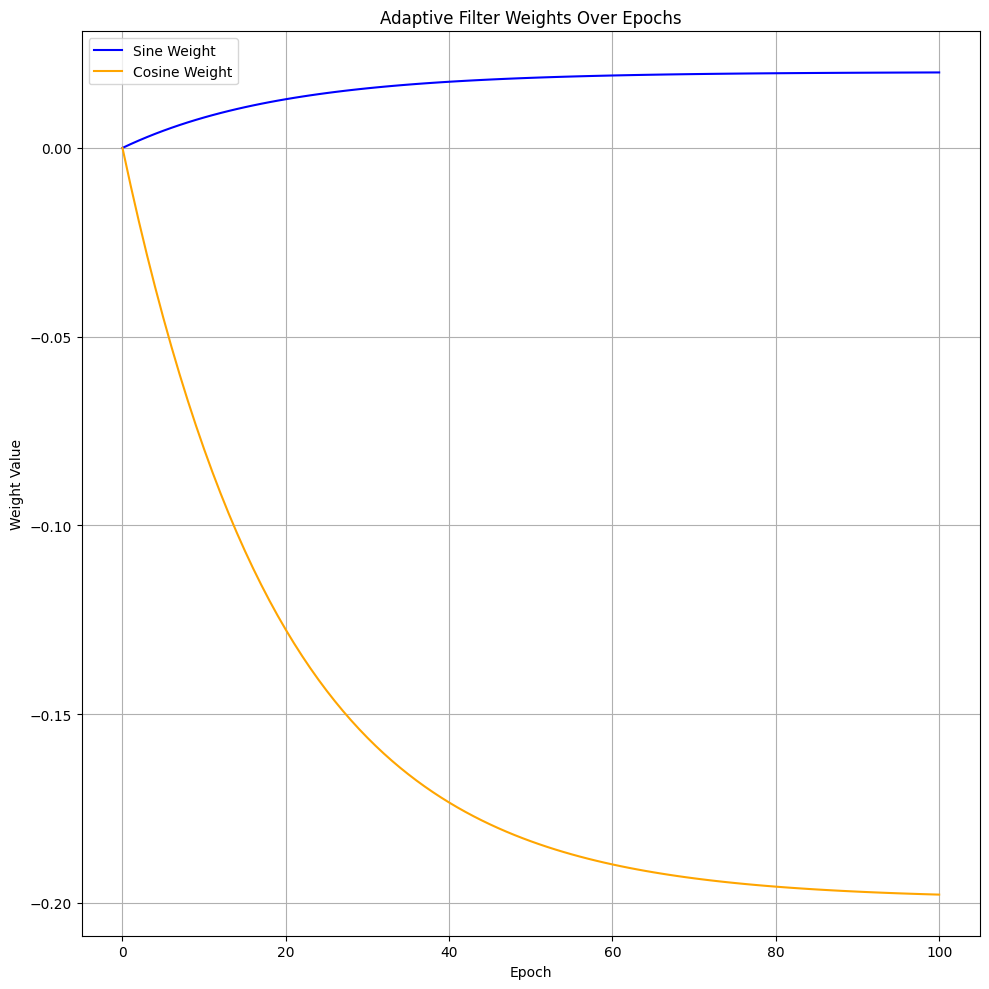

In [5]:
fig0, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.plot(weights_history[:, 0], label='Sine Weight', color='blue')
ax.plot(weights_history[:, 1], label='Cosine Weight', color='orange')
ax.set_title('Adaptive Filter Weights Over Epochs')
ax.set_xlabel('Epoch')
ax.set_ylabel('Weight Value')
ax.legend()
ax.grid()
plt.tight_layout()

As expected, the sine and cosine filter weight graph shows that the weight values ​​become closer to the original values ​​after the epochs pass and the slope of their changes becomes smaller.

4. Implement FIR and IIR filters to remove the power line noise from the recorded signal. Compare the results of the adaptive filter with the FIR and IIR filters.

`design_fir_notch()` creates a finite impulse response bandstop filter using windowing method to remove specific frequency components. Offers linear phase response but requires many coefficients for sharp frequency selectivity.

`design_iir_notch()` designs an infinite impulse response notch filter using poles and zeros placement for targeted frequency removal. Provides computational efficiency but introduces phase distortion.

**Filter Design Functions**

`signal.firwin()`: Window-based FIR filter design method

- Creates filter coefficients using specified window function (Blackman-Harris)
- pass_zero='bandstop' creates notch characteristics
- Window reduces spectral leakage and sidelobe levels


`signal.iirnotch()`: Designs second-order IIR notch filter

- Places zeros at target frequency and poles slightly inside unit circle
- Returns numerator (b) and denominator (a) coefficients
- Automatically handles digital frequency scaling


`signal.tf2sos()`: Converts transfer function to second-order sections

- Transforms b,a coefficients into cascaded biquad sections
- Improves numerical stability for high-order filters
- Reduces quantization errors in fixed-point implementations

**Filter Application Functions**

`signal.lfilter()`: Applies FIR/IIR filter using direct form

- Linear convolution for FIR (when denominator = 1.0)
- Processes signal sample-by-sample with feedback for IIR
- Maintains internal states for recursive filtering


`signal.sosfilt()`: Filters using second-order sections

- Cascades multiple biquad filters for stability
- More robust than direct form for high Q factors
- Preferred method for IIR filtering implementation

In [6]:
def design_fir_notch(sample_rate, noise_freq, Q, numtaps):
    """
    FIR filter design using the window method.

    Parameters:
        sample_rate (int): Sampling frequency in Hz
        noise_freq (float): Notch frequency to remove (Hz)
        Q (float): Quality factor (higher = narrower notch)
        numtaps (int): Number of filter coefficients (odd recommended)

    Returns:
        b (ndarray): FIR filter coefficients
    """

    nyquist = 0.5 * sample_rate
    width = noise_freq / Q
    bands = [max(0, noise_freq - width/2), min(nyquist, noise_freq + width/2)]

    b = signal.firwin(numtaps,
                      bands,
                      fs=sample_rate,
                      pass_zero='bandstop',
                      window='blackmanharris')
    return b

def design_iir_notch(sample_rate, noise_freq, Q):
    """
    A second-order IIR notch digital filter.

    Parameters:
        sample_rate (int): Sampling frequency in Hz
        noise_freq (float): Notch frequency to remove (Hz)
        Q (float): Quality factor (higher = narrower notch)

    Returns:
        sos (ndarray): Second-order sections coefficients
    """

    b, a = signal.iirnotch(noise_freq, Q, fs=sample_rate)
    sos = signal.tf2sos(b, a)
    return sos

fir_coeffs = design_fir_notch(sample_rate, noise_freq, 30, 2001)
fir_cleaned = signal.lfilter(fir_coeffs, 1.0, noisy_signal)

iir_sos = design_iir_notch(sample_rate, noise_freq, 30)
iir_cleaned = signal.sosfilt(iir_sos, noisy_signal)

We're going to compare filters in Part 5 after ploting them.

5. Plot the original signal, the noisy signal, and the filtered signals. Write functions to play the audio signals.

In [7]:
# Compute FFT
N = len(noisy_signal)
xfreq = fftfreq(N, 1/sample_rate)
orig_freq = fft(original_signal)
noisy_freq = fft(noisy_signal)
adaptive_freq = fft(adaptive_cleaned)
fir_freq = fft(fir_cleaned)
iir_freq = fft(iir_cleaned)

`plot_time_and_freq()`: Creates dual-domain visualization (time and frequency)

- Time plot: Shows signal amplitude vs time using `ax.plot(t, signal)`
- Frequency plot: Displays magnitude spectrum using `abs(signal_freq)`
- `xlim(0, sample_rate/20)`: Limits frequency display to relevant range

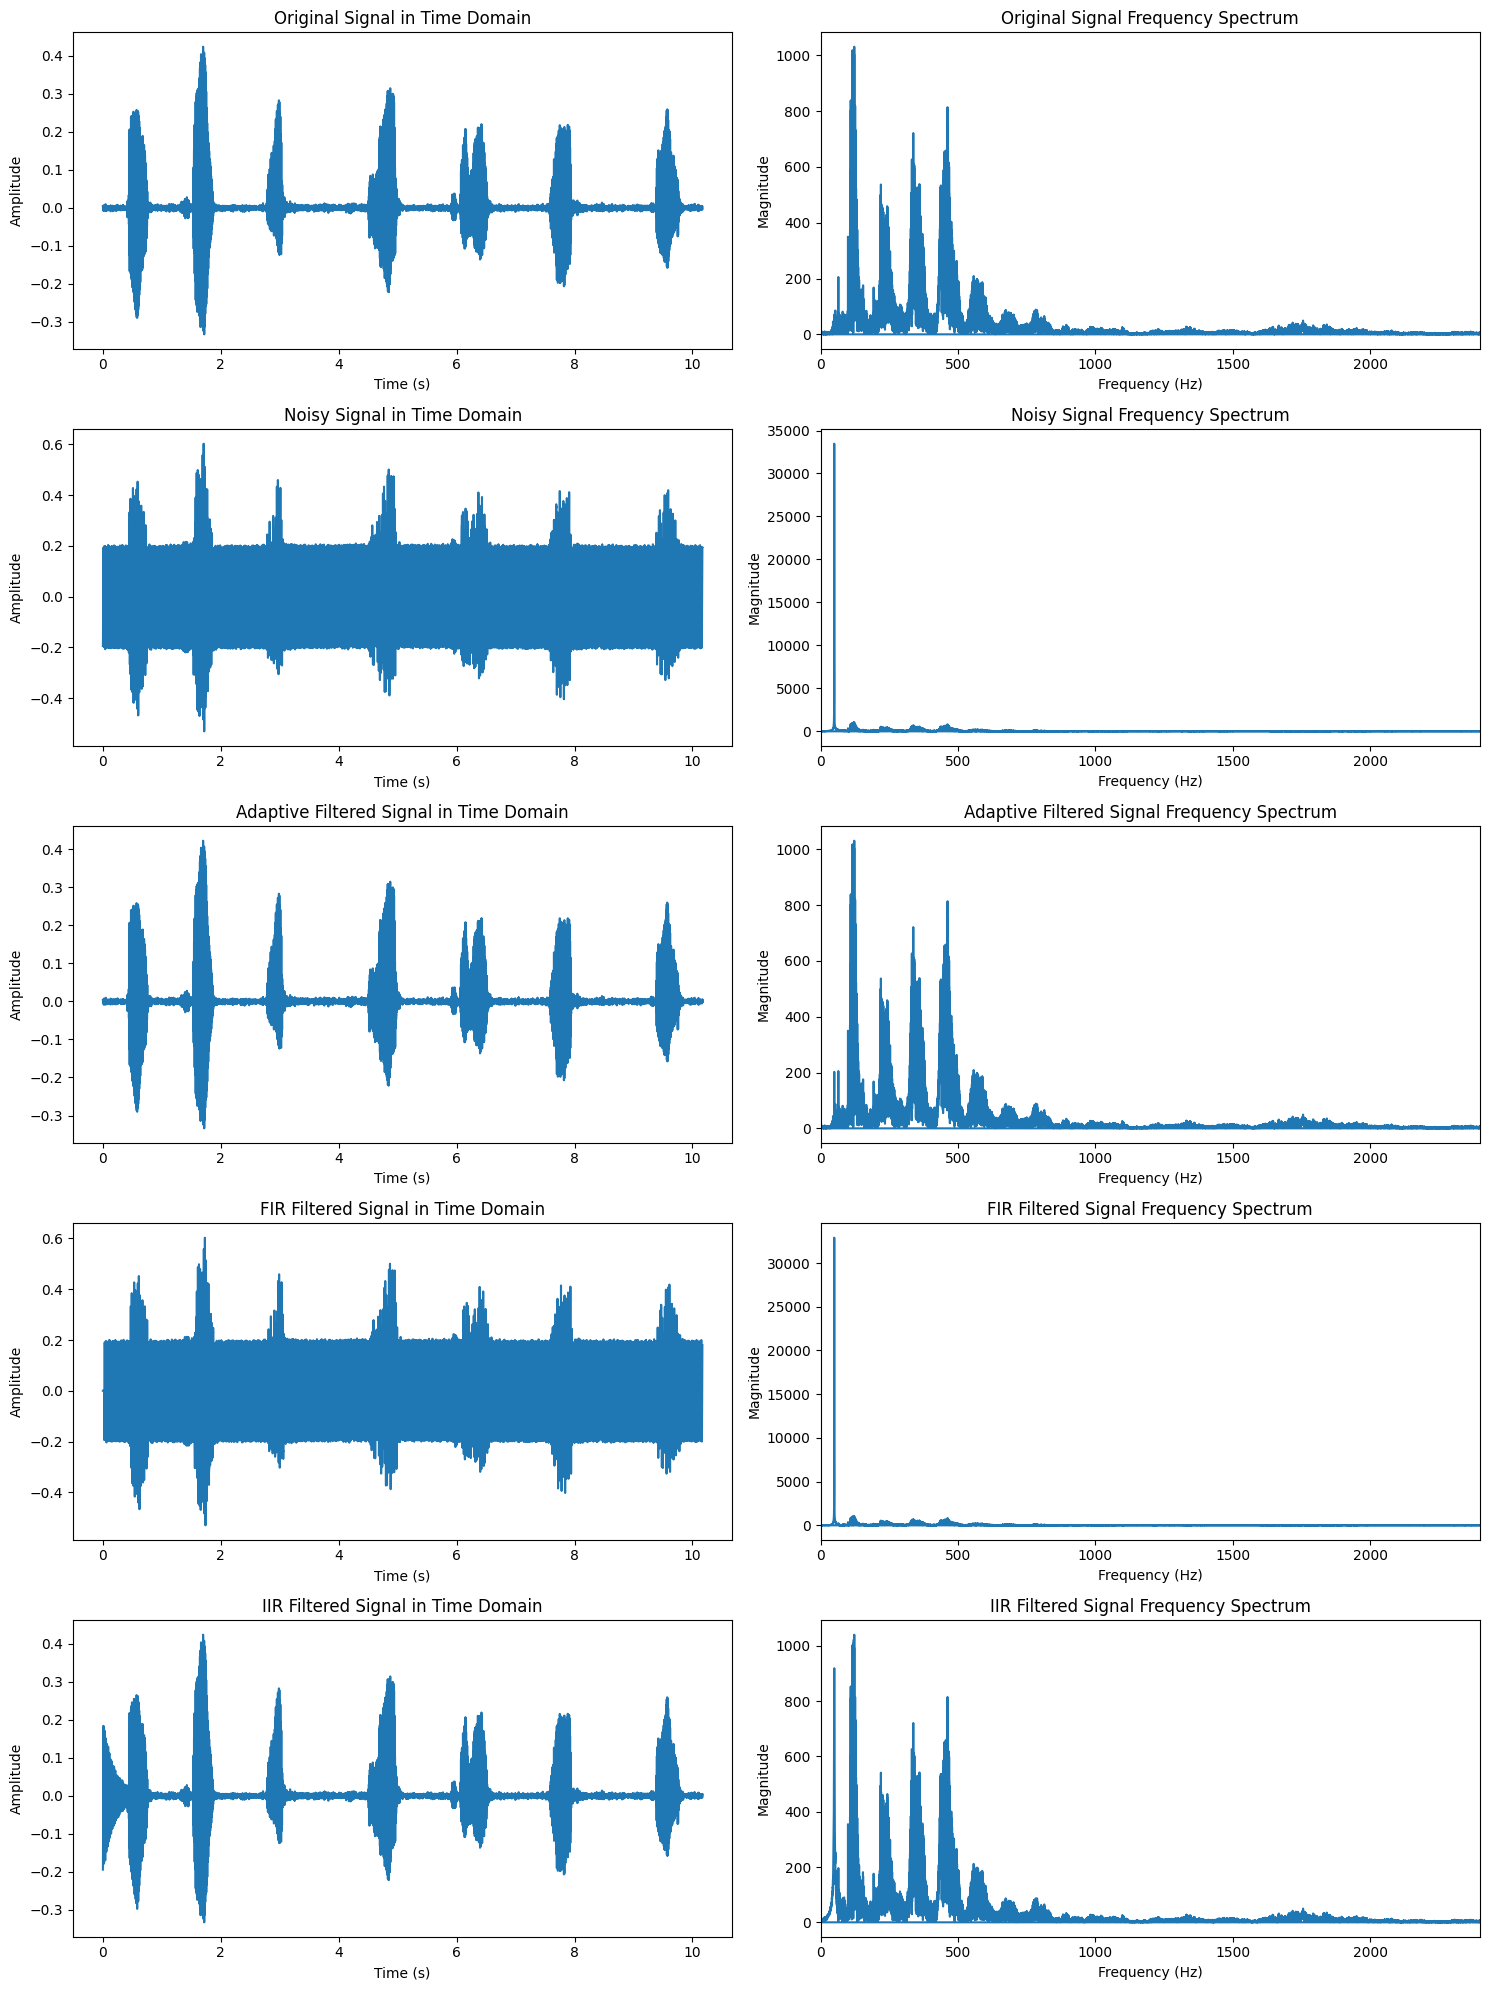

In [8]:
# Plot
def plot_time_and_freq(ax_row, t, signal_time, xfreq, signal_freq, title_prefix, sample_rate):
    # Time domain
    ax_row[0].plot(t, signal_time)
    ax_row[0].set_title(f'{title_prefix} in Time Domain')
    ax_row[0].set_xlabel('Time (s)')
    ax_row[0].set_ylabel('Amplitude')

    # Frequency domain
    ax_row[1].plot(xfreq, abs(signal_freq))
    ax_row[1].set_title(f'{title_prefix} Frequency Spectrum')
    ax_row[1].set_xlim(0, sample_rate / 20)
    ax_row[1].set_xlabel('Frequency (Hz)')
    ax_row[1].set_ylabel('Magnitude')

fig1, ax = plt.subplots(5, 2, figsize=(15, 20))

# Plot all signals
plot_time_and_freq(ax[0], t, original_signal, xfreq, orig_freq, 'Original Signal', sample_rate)
plot_time_and_freq(ax[1], t, noisy_signal, xfreq, noisy_freq, 'Noisy Signal', sample_rate)
plot_time_and_freq(ax[2], t, adaptive_cleaned, xfreq, adaptive_freq, 'Adaptive Filtered Signal', sample_rate)
plot_time_and_freq(ax[3], t, fir_cleaned, xfreq, fir_freq, 'FIR Filtered Signal', sample_rate)
plot_time_and_freq(ax[4], t, iir_cleaned, xfreq, iir_freq, 'IIR Filtered Signal', sample_rate)

fig1.tight_layout()

##### Plot analysis

- Original Signal Characteristics (Row 1)
In the first row displaying the original signal, individual spoken words are clearly distinguishable in the time domain plot, with the signal's frequency content concentrated primarily between 0-500 Hz, which is typical for speech signals.

- Noisy Signal Analysis (Row 2)
After adding 50 Hz power line noise to the original signal, the contamination is evident in the time domain plot. The noise amplitude is clearly visible relative to the original signal, matching the configured amplitude of 0.2. In the frequency domain, a prominent peak appears at 50 Hz, representing the added interference.

- Adaptive Filter Performance (Row 3)
Following application of the adaptive LMS filter, the noise has been significantly reduced, making the time domain signal closely resemble the original clean signal. In the frequency domain, the 50 Hz peak has been substantially attenuated, demonstrating effective noise cancellation.

- FIR Filter Performance (Row 4)
After applying the FIR notch filter, the performance is suboptimal as this filter design does not provide satisfactory results. The noise remains clearly visible, indicating inadequate noise suppression capabilities.

- IIR Filter Performance (Row 5)
The IIR notch filter successfully removes the target noise, though its performance is inferior to the adaptive filter. While effective at noise cancellation, it shows reduced performance compared to the adaptive LMS approach in terms of overall signal quality preservation.

---

`plot_spectrum()`: Compares multiple signals in frequency domain

- Uses `semilogy()` for logarithmic magnitude scale
- Overlays original, noisy, and cleaned spectra with transparency (alpha=0.7)
- `xlim(0, 150)`: Focuses on low frequencies where power line noise exists

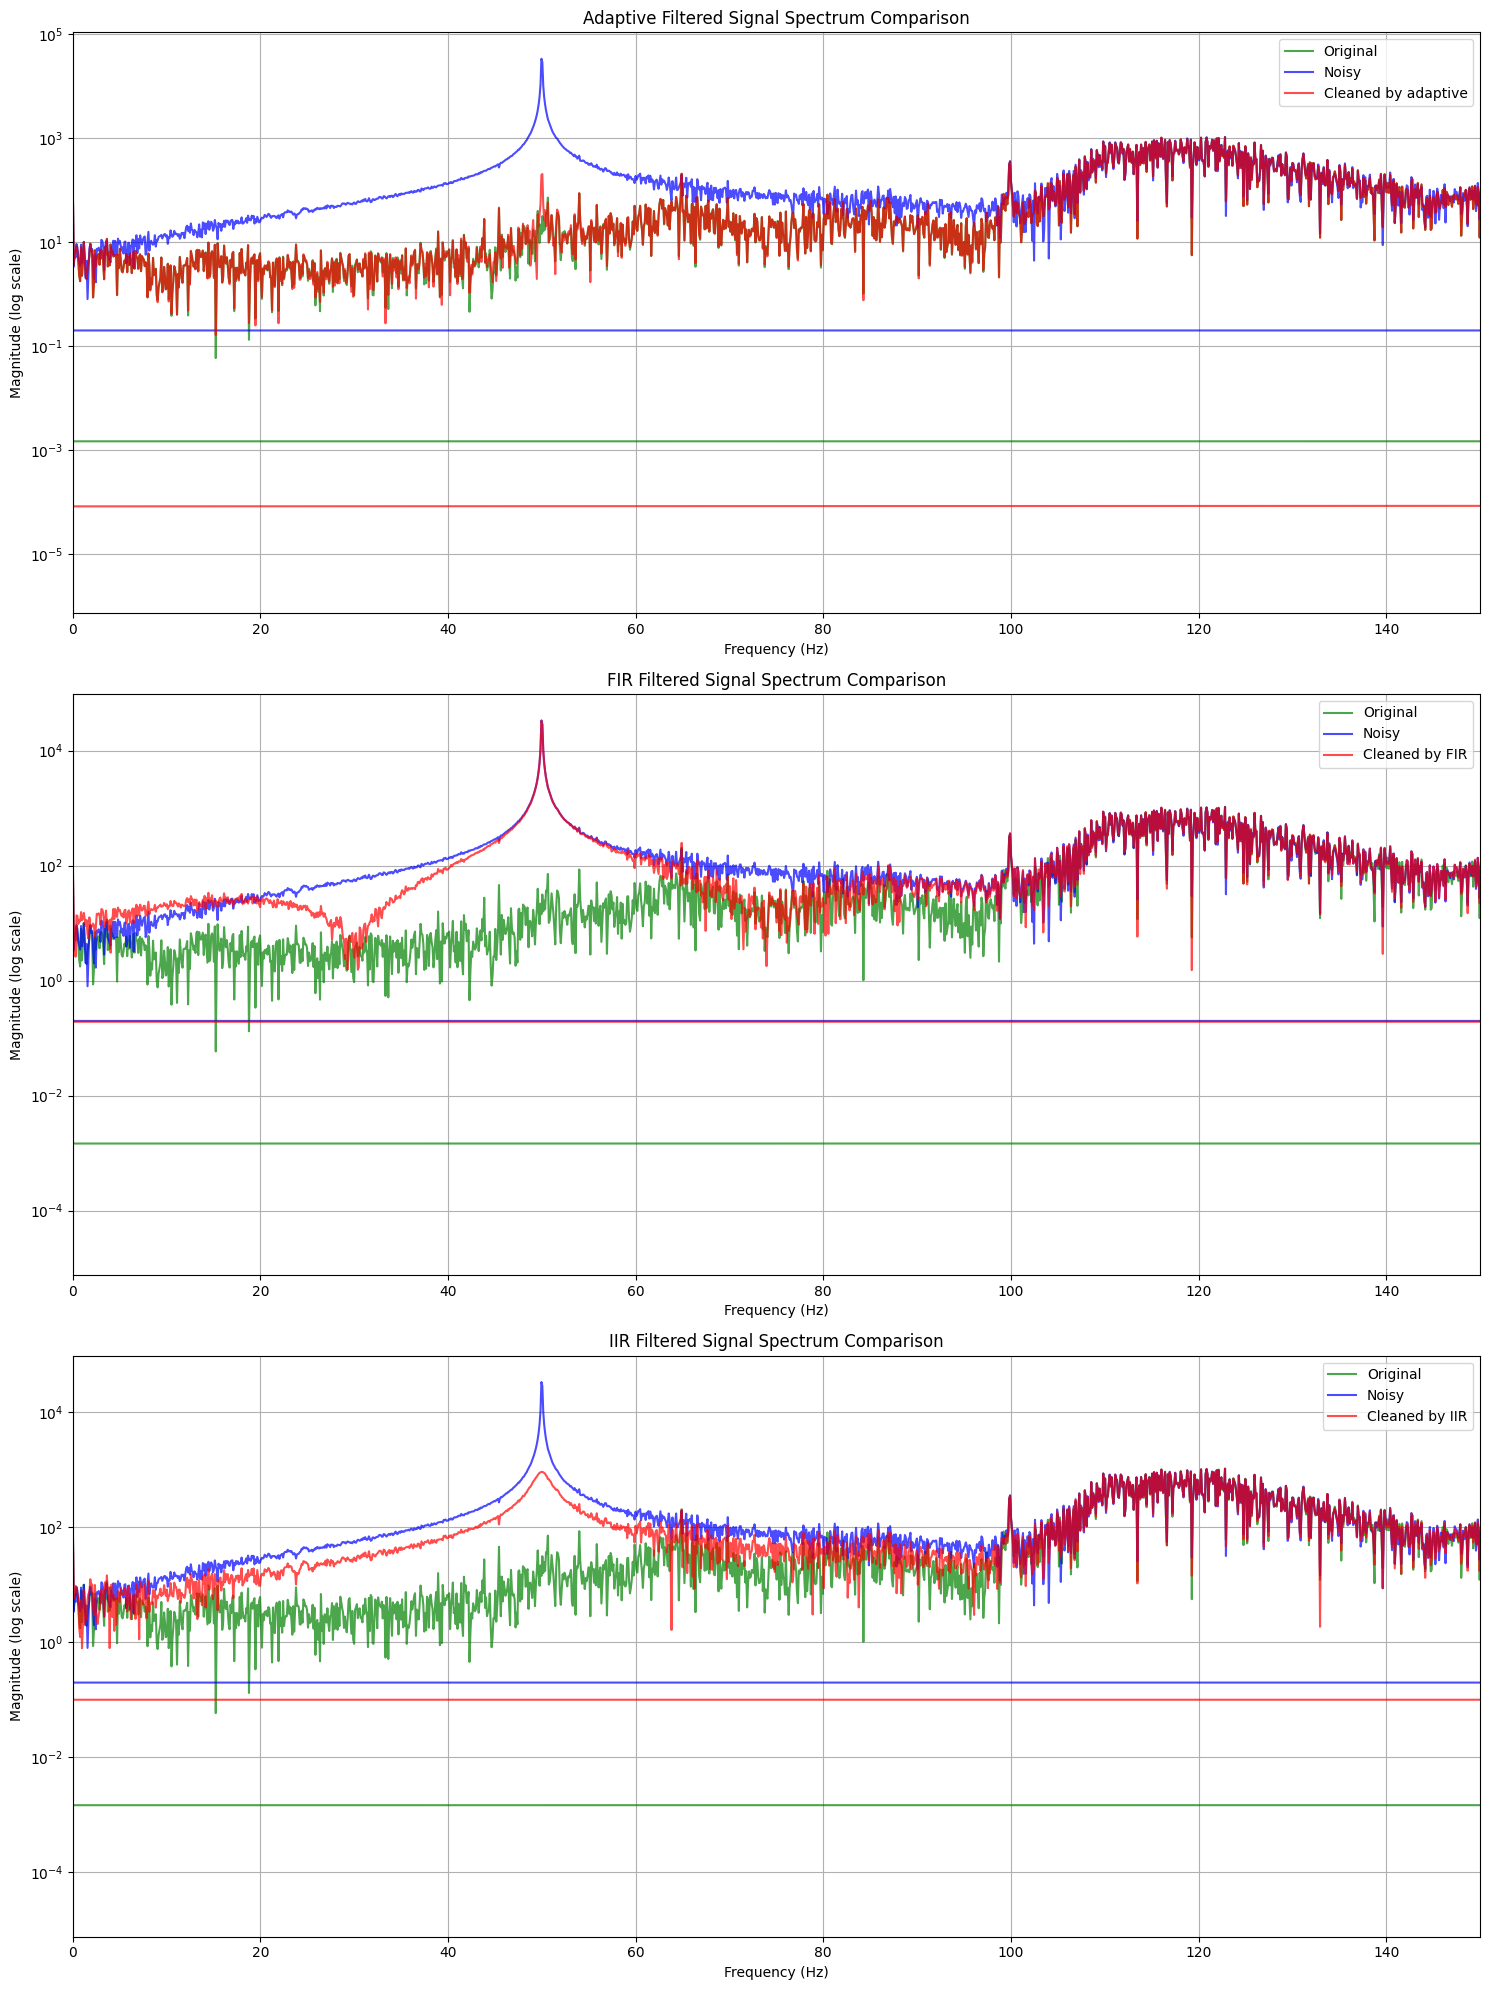

In [9]:
def plot_spectrum(ax, xfreq, orig_freq, noisy_freq, cleaned_freq, label, title):
    ax.semilogy(xfreq, abs(orig_freq), 'g', label='Original', alpha=0.7)
    ax.semilogy(xfreq, abs(noisy_freq), 'b', label='Noisy', alpha=0.7)
    ax.semilogy(xfreq, abs(cleaned_freq), 'r', label=label, alpha=0.7)
    ax.set_xlim(0, 150)
    ax.set_title(title)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude (log scale)')
    ax.legend()
    ax.grid(True)

fig2, ax = plt.subplots(3, 1, figsize=(15, 20))

plot_spectrum(ax[0], xfreq, orig_freq, noisy_freq, adaptive_freq, 'Cleaned by adaptive', 'Adaptive Filtered Signal Spectrum Comparison')
plot_spectrum(ax[1], xfreq, orig_freq, noisy_freq, fir_freq, 'Cleaned by FIR', 'FIR Filtered Signal Spectrum Comparison')
plot_spectrum(ax[2], xfreq, orig_freq, noisy_freq, iir_freq, 'Cleaned by IIR', 'IIR Filtered Signal Spectrum Comparison')

fig2.tight_layout()

- Adaptive Filter Spectrum Comparison
The subsequent spectral plots demonstrate that the adaptive filter not only eliminates the 50 Hz noise component but also produces a filtered signal that closely matches the original signal's frequency characteristics across the entire spectrum.

- FIR Filter Spectrum Analysis
The second comparison plot reveals poor FIR filter performance, showing minimal noise attenuation at the target frequency. The filter introduces unwanted distortion by slightly affecting frequencies above 50 Hz while bringing some frequencies below 50 Hz closer to the original signal levels. Overall, this filter performs inadequately, causing more signal degradation than noise removal.

- IIR Filter Spectrum Evaluation
The third comparison plot shows that the IIR filter demonstrates good performance in noise attenuation, successfully bringing the noisy signal's frequency components closer to those of the original signal. However, its overall performance remains inferior to the adaptive filter's capabilities in terms of spectral fidelity and noise suppression effectiveness.

---

To more accurately compare the filters, we used **snr** and **noise reduction** comparison criteria.

`calculate_snr()`: Computes Signal-to-Noise Ratio in dB

- Formula: $SNR = 10 * log10(signal_power / noise_power)$
- Higher values indicate better signal quality
- Uses mean squared power: `np.mean(signal**2)`


`calculate_improvement()`: Measures noise reduction effectiveness

- Compares original noise vs residual noise after filtering
- Formula: $Improvement = 10 * log10(original_noise / residual_noise)$
- Positive values indicate successful noise reduction

In [10]:
def calculate_snr(clean, noisy):
    """Calculate Signal-to-Noise Ratio (dB)"""
    signal_power = np.mean(clean**2)
    noise_power = np.mean((clean - noisy)**2)
    return 10 * np.log10(signal_power / noise_power)

def calculate_improvement(original, noisy, cleaned):
    """Calculate noise reduction in dB"""
    original_noise = np.mean((original - noisy)**2)
    residual_noise = np.mean((original - cleaned)**2)
    return 10 * np.log10(original_noise / residual_noise)

# Original SNR (clean signal vs noisy)
original_snr = calculate_snr(original_signal, noisy_signal)

# Results table
print("\n" + "="*60)
print("Noise Cancellation Performance Comparison")
print("="*60)
print(f"{'Method':<15} | {'Output SNR (dB)':<15} | {'Noise Reduction (dB)':<20}")
print("-"*60)

def print_result(method_name, cleaned_signal):
    snr = calculate_snr(original_signal, cleaned_signal)
    improvement = calculate_improvement(original_signal, noisy_signal, cleaned_signal)
    print(f"{method_name:<15} | {snr:15.2f} | {improvement:20.2f}")
    return snr, improvement

print_result("Original", noisy_signal)
fir_snr, fir_impr = print_result("FIR", fir_cleaned)
iir_snr, iir_impr = print_result("IIR", iir_cleaned)
adaptive_snr, adaptive_impr = print_result("Adaptive LMS", adaptive_cleaned)
print("="*60)

# Recommendation
best_method = np.argmax([fir_impr, iir_impr, adaptive_impr])
methods = ["FIR", "IIR", "Adaptive LMS"]
print(f"\nRecommendation: {methods[best_method]} filter provides the best noise reduction")


Noise Cancellation Performance Comparison
Method          | Output SNR (dB) | Noise Reduction (dB)
------------------------------------------------------------
Original        |          -10.50 |                 0.00
FIR             |          -11.23 |                -0.73
IIR             |            9.76 |                20.26
Adaptive LMS    |           33.91 |                44.41

Recommendation: Adaptive LMS filter provides the best noise reduction


**Quantitative Performance Validation**
Using SNR and noise reduction metrics, we can validate our observations with precise numerical evidence and provide accurate performance assessment.

- FIR Filter Performance Analysis
As clearly demonstrated by the quantitative results, the FIR filter not only fails to attenuate the target noise but actually introduces additional signal distortion, degrading the original signal quality rather than improving it.

- IIR Filter Performance Analysis
The IIR filter successfully removes the noise interference, showing substantial improvement in both SNR and noise reduction metrics compared to the contaminated signal.

- Adaptive Filter Superior Performance
The adaptive LMS filter achieves exceptional noise reduction of 44 dB, demonstrating significantly superior performance compared to the IIR filter. This substantial noise attenuation validates the adaptive filter's effectiveness in real-time interference cancellation.

**Final Recommendation**
Based on comprehensive quantitative analysis, the adaptive filter demonstrates the best overall performance, providing optimal noise cancellation while preserving signal integrity.

---

`save_wav()`: Exports processed signals as WAV files

- `np.clip(signal, -1.0, 1.0)`: Prevents clipping distortion
- Converts float32 to int16 PCM format: `(signal * 32767).astype(np.int16)`
- Saves to `"outputs/"` directory for comparison

In [11]:
# Save
fig1.savefig('../outputs/ResultsInTimeAndFreq.png')
fig2.savefig('../outputs/ResultsComparedToOriginal.png')

def save_wav(filename, signal, sample_rate):
    """
    Save a floating-point signal in range [-1, 1] as a 16-bit PCM WAV file.
    """
    clipped = np.clip(signal, -1.0, 1.0)
    int16_signal = (clipped * 32767).astype(np.int16)
    wavfile.write("../outputs/" + filename, sample_rate, int16_signal)

save_wav('original_signal.wav', original_signal, sample_rate)
save_wav('noisy_signal.wav', noisy_signal, sample_rate)
save_wav('adaptive_cleaned.wav', adaptive_cleaned, sample_rate)
save_wav('fir_cleaned.wav', fir_cleaned, sample_rate)
save_wav('iir_cleaned.wav', iir_cleaned, sample_rate)

### Decoding:

#### Noise-free:

1. Extract the hidden message.

##### The Decoding Process: 

1.  **Read the WAV File**: 
    First, it opens the specified `.wav` audio file and reads its contents. It gets two key things: the *sample rate* (how many sound measurements are taken per second) and the *audio samples* themselves (the numerical data representing the sound).

2.  **Ensure Mono Audio**:
    Many audio files are in stereo (left and right channels). To keep things simple, if the audio is stereo, the script usually just picks one channel (typically the left one) to work with.

3.  **Normalize**:
    Often, audio samples (especially 16-bit ones) are read as integers. They might be converted to a standard floating-point range (like -1.0 to 1.0) first.

4.  **Apply Scaling**:
    The script then multiplies the samples by a specific factor (`attenuation`). This is likely designed to **reverse** a step taken during the *encoding* process. The encoder might have scaled *down* the samples before embedding the LSBs; this scaling *up* helps ensure the integer values are in the expected range for LSB extraction.

5.  **Round to Integers**:
    After scaling, the samples are converted back into whole numbers (integers). This is essential because LSB operations are performed on the binary (integer) representation of the numbers.

6.  **Select Specific Samples**:
    This is a crucial detail! The message isn't hidden in *every single* sample. Instead, the script starts at a particular sample (e.g., the 2625th) and then jumps forward by a fixed interval (`sample_multiple`) to pick the next sample. This means the hidden bits are spread out, making them harder to find and less likely to create noticeable patterns. *You must know this interval to decode the message correctly.*

7.  **Extract LSBs**:
    For each *selected* sample, the script looks at its binary representation and picks out only the very last bit (the LSB). It does this using a bitwise `AND` operation with 1. If the LSB is 1, the result is 1; if it's 0, the result is 0. These extracted 0s and 1s are the raw bits of our hidden message.

In [12]:
def decode_lsb_from_wav(filename, sample_multiple=2625, attenuation=100):

    try:
        sample_rate, samples = wavfile.read(filename) 
    except FileNotFoundError:
        print(f"Error: The file '{filename}' was not found.")
        return ""

    # If stereo, take only the first channel
    if samples.ndim > 1:
        samples = samples[:, 0]

    # Normalize samples
    if samples.dtype == np.int16:
        samples = samples / 32768.0  # Max value for int16
    elif samples.dtype == np.int32:
        samples = samples / 2147483648.0 # Max value for int32

    # Apply attenuation 
    samples = samples * attenuation

    # Round to nearest integer 
    samples = np.round(samples).astype(int)     

    # Select every Nth sample, starting from the (N-1)th index
    if sample_multiple > 0:
        selected_samples = samples[(sample_multiple-1)::sample_multiple]
    else:
        print("Error: sample_multiple must be greater than 0.")
        return ""

    # Extract the LSB (0 or 1) from each selected sample
    lsb_bits = (selected_samples & 1)

    # Convert the extracted bits to text using the new function
    hidden_message = bits_to_text(lsb_bits)

    return hidden_message

def decode_lsb_from_signal(samples, sample_multiple=2625, attenuation=100):

    # If stereo, take only the first channel
    if samples.ndim > 1:
        samples = samples[:, 0]

    # Normalize samples
    if samples.dtype == np.int16:
        samples = samples / 32768.0  # Max value for int16
    elif samples.dtype == np.int32:
        samples = samples / 2147483648.0 # Max value for int32

    # Apply attenuation 
    samples = samples * attenuation

    # Round to nearest integer 
    samples = np.round(samples).astype(int)     

    # Select every Nth sample, starting from the (N-1)th index
    if sample_multiple > 0:
        selected_samples = samples[(sample_multiple-1)::sample_multiple]
    else:
        print("Error: sample_multiple must be greater than 0.")
        return ""

    # Extract the LSB (0 or 1) from each selected sample
    lsb_bits = (selected_samples & 1)

    # Convert the extracted bits to text using the new function
    hidden_message = bits_to_text(lsb_bits)

    return hidden_message

def bits_to_text(lsb_bits):

    lsb_bits = lsb_bits.astype(str)

    message_bytes = []
    # Iterate over the bits in chunks of 8 to form bytes
    for i in range(0, len(lsb_bits), 8):
        byte_bits = lsb_bits[i:i+8]
        # Ensure we have a full byte
        if len(byte_bits) < 8:
            break 
        # Join the bits in the byte and convert to an integer
        byte_str = ''.join(byte_bits)
        message_bytes.append(int(byte_str, 2))

    # Convert byte integers to characters
    hidden_message = ''.join([chr(b) for b in message_bytes])

    # Find the null terminator and truncate the message if found
    null_index = hidden_message.find('\x00')
    if null_index != -1:
        hidden_message = hidden_message[:null_index]

    return hidden_message

##### The Translator: How Turn Bits into Text

1.  **Reconstruct Bytes**:
    Computers understand data in groups of 8 bits, called *bytes*. The script takes the long sequence of extracted LSBs and groups them into chunks of 8.

2.  **Convert Bytes to Characters**:
    Each 8-bit byte corresponds to a character. The script converts each byte back into its character equivalent.

3. **Assemble & Clean Up**:
    All the characters are joined together to form the hidden message. Often, a special "null character" (`\x00`) is used to mark the *end* of the hidden message. The script looks for this null character and cuts off anything that might come after it, ensuring we only get the intended message.

##### Result:

In [13]:
hidden_message = decode_lsb_from_wav("../inputs/100-2625.wav")

if hidden_message:
    print("Hidden message:", hidden_message)
else:
    print("No message decoded or an error occurred.")

Hidden message: Signals & System


#### Noisy audio:

1. Plot the signal in the frequency domain. Determine the noise frequencies in the audio by performing an analysis of its frequency spectrum using FFT.

##### Analyzing Noise in a WAV File:

1.  **Read the WAV File**: 
    First, it opens the specified `.wav` audio file and reads its contents. It gets two key things: the *sample rate* (how many sound measurements are taken per second) and the *audio samples* themselves (the numerical data representing the sound).

2.  **Ensure Mono Audio**:
    Many audio files are in stereo (left and right channels). To keep things simple, if the audio is stereo, the script usually just picks one channel (typically the left one) to work with.

3.  **Transform to the Frequency Domain (FFT)**:
    The core of the analysis involves converting the audio signal from the time domain (how amplitude changes over time) to the frequency domain (which frequencies are present and how strong they are).
    This is achieved using the Fast Fourier Transform (FFT). The `fft()` function takes the audio samples and outputs a set of complex numbers. Each complex number corresponds to a specific frequency and encodes both the strength (magnitude) and phase of that frequency component in the original signal.

4.  **Calculate Frequency Magnitudes & Normalize**:
    From the complex FFT output, we're primarily interested in the magnitude (or strength) of each frequency. This is calculated by taking the absolute value of each complex number.
    Crucially, these raw magnitudes are then normalized by dividing them by the total number of samples in the audio. This step is important because the raw FFT output scales with the length of the signal. Normalization makes the magnitude values independent of the audio clip's duration, allowing for more consistent comparisons and a better representation of the actual amplitude of frequency components.

5.  **Determine Corresponding Frequencies**:
    The FFT output gives us magnitudes, but we also need to know which actual frequency (in Hz) each magnitude corresponds to.
    The `fftfreq()` function is used for this. It generates an array of frequency values that align with the FFT output, based on the total number of samples and the original sample rate.

6.  **Focus on Positive Frequencies**:
    For real-world audio signals, the FFT output is symmetrical: the information in negative frequencies mirrors that in positive frequencies.
    Therefore, we typically only need to analyze one half of the spectrum. The code selects the portion of the frequencies and fft_magnitude arrays that correspond to 0 Hz and positive frequencies.

7.  **Identify Dominant Peaks (Potential Noise)**:
    The function assumes that the most prominent "noise" will appear as the highest peaks in the frequency spectrum.
    It sets a target (num_peaks_to_find, e.g., 2) for how many of the loudest frequencies to identify.
    It then finds the indices of these highest magnitude peaks in the positive_fft_magnitude array.

8.  **Extract Noise Frequencies**:
    Using the indices of the identified peaks, the function looks up the corresponding actual frequency values (in Hz) from the positive_frequencies array. These are considered the detected noise frequencies.

In [14]:
def analysis_noisy_Wav(filename):

    sample_rate, samples = wavfile.read(filename)

    if samples.ndim > 1:
        samples = samples[:, 0]

    fft_output = fft(samples)
    fft_magnitude = np.abs(fft_output) / len(samples)
    frequencies = fftfreq(len(samples), 1 / sample_rate)

    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_fft_magnitude = fft_magnitude[:len(fft_magnitude)//2]

    num_peaks_to_find = 2
    peak_indices = np.argsort(positive_fft_magnitude)[-num_peaks_to_find:]
    noise_frequencies_found = positive_frequencies[peak_indices]
    print(f"Detected Noise Frequencies: {noise_frequencies_found[0]} Hz and {noise_frequencies_found[1]:.2f} Hz")


    plt.figure(figsize=(12, 6))
    plt.plot(positive_frequencies, positive_fft_magnitude)
    plt.scatter(noise_frequencies_found, positive_fft_magnitude[peak_indices], color='red', s=100, label='Detected Noise Frequencies')
    plt.title(f'Frequency Spectrum of "{filename}"')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()

##### Result:

Detected Noise Frequencies: 2500.05 Hz and 1500.06 Hz


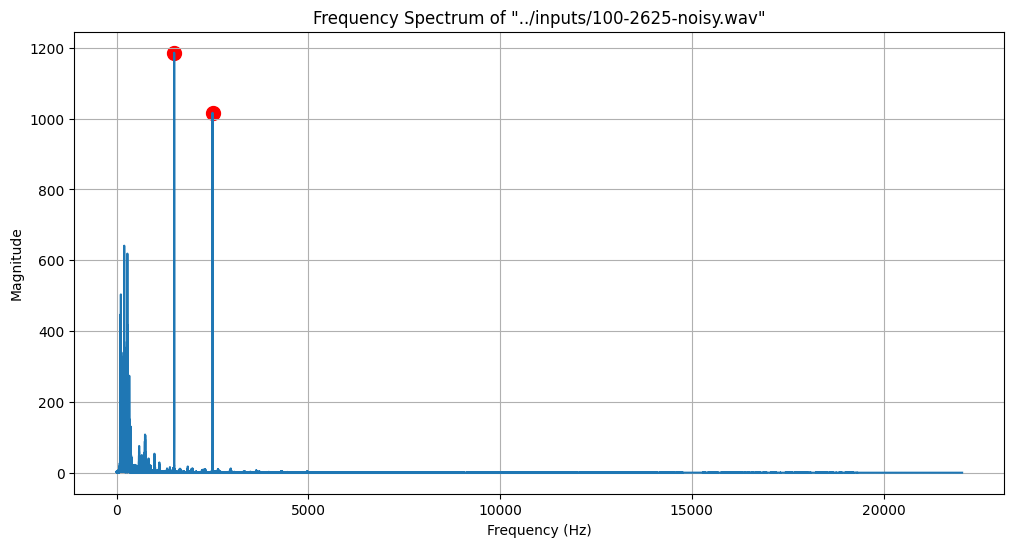

In [15]:
analysis_noisy_Wav("../inputs/100-2625-noisy.wav")

2. Based on the previous section (noise cancelling), design a filter to remove the noise effectively. Note that you must adjust the order or quality factor of your filter in such a way that the samples remain unchanged. By comparing the FFT of the signal before and after filtering, you can design the filter effectively. After applying the filter, plot the signal in both the time and frequency domains to ensure that the noise has been effectively removed. If you are using a filter that was not mentioned in the previous section, be sure to first include an explanation of that filter in your report file.

---

##### `plot_fft` Function Explanation

**Purpose:**

The `plot_fft` function is designed to visualize the Fast Fourier Transform (FFT) spectrum of a signal.

**Why It Wasn't Used in the Past?**

Previously, we avoided using `plot_fft` in certain processing pipelines because:
1. The signal was already in the frequency domain (FFT had already been applied), Applying IFFT to get back to time domain just to use `plot_fft` would mean: First IFFT to convert to time domain, Then FFT again inside `plot_fft` to get back to frequency domain. This double transformation was computationally inefficient
2. We need to plt other information in same figure


In [16]:
def plot_fft(samples, sample_rate, plot_title, x_max_val=None):

    fft_output = fft(samples)
    fft_magnitude = np.abs(fft_output) / len(samples)
    frequencies = fftfreq(len(samples), 1 / sample_rate)

    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_fft_magnitude = fft_magnitude[:len(fft_magnitude)//2]

    plt.figure(figsize=(12, 6))
    plt.plot(positive_frequencies, positive_fft_magnitude)
    plt.title(f'Frequency Spectrum of "{plot_title}"')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.xlim(0, x_max_val if x_max_val else sample_rate / 2)
    plt.show()

##### `find_closest_bin` Function

**Purpose:**

Finds the frequency bin in a frequency array that is closest to a target frequency value.

**How it works:**

1. Calculates the absolute difference between each frequency in `freqs_array` and the `target_freq_value`
2. Returns the index (bin number) of the smallest difference using `np.argmin()`

**Mathematically:**

Returns `i` such that `|freqs_array[i] - target_freq_value|` is minimized

In [17]:
def find_closest_bin(freqs_array, target_freq_value):
    return np.argmin(np.abs(freqs_array - target_freq_value))

In [18]:
def load_and_prepare_audio(filename):

    try:
        sample_rate, samples = wavfile.read(filename) 
    except FileNotFoundError:
        print(f"Error: The file '{filename}' was not found.")
        return ""

    if samples.ndim > 1:
        samples = samples[:, 0]

    if samples.dtype == np.int16:
        samples = samples / 32768.0  # Max value for int16
    elif samples.dtype == np.int32:
        samples = samples / 2147483648.0 # Max value for int32

    samples_len = len(samples)

    return sample_rate, samples, samples_len

---

##### `perform_fft_analysis` &  `perform_ifft_and_get_real` Function

**frequency_resolution:**
```text
Low Resolution (10Hz)       High Resolution (1Hz)
|--------|--------|         |-|-|-|-|-|-|-|-|-|-|
0 Hz    10 Hz    20 Hz      0 1 2 3 ... 9 10 Hz

In [19]:
def perform_fft_analysis(samples_to_fft, samples_rate):
    fft_spectrum = fft(samples_to_fft)
    fft_frequencies = fftfreq(len(samples_to_fft), 1 / samples_rate)
    frequency_resolution = samples_rate / len(samples_to_fft)
    return fft_spectrum, fft_frequencies, frequency_resolution

def perform_ifft_and_get_real(processed_fft_spectrum):
    time_domain_complex = ifft(processed_fft_spectrum)
    time_domain_real = np.real(time_domain_complex)
    return time_domain_real

---

##### Noise Removal in Frequency Spectrum using `linear interpolation`

**Purpose**

This function removes specific noise frequencies from an FFT spectrum by replacing them with smoothly interpolated values from nearby clean frequencies.

**How It Works?**

1. Preparation
    - Makes a copy of the original spectrum to avoid modifying the input data
    - Calculates how many frequency bins need to be replaced based on:
      - `noise_window_hz`: How wide the noise is (in Hz)
      - `freq_res`: The frequency resolution (Hz per bin)

2. For Each Target Noise Frequency
For every noise frequency you want to remove:

      a) Find the Noise
      - Locates the exact frequency bin where the noise is centered
      - Calculates a window of bins around it that will be replaced

      b) Find Clean Reference Points
      - Identifies "clean" bins just outside the noise window to use as reference points
    
      c) Replace the Noise
      - Performs linear interpolation between the clean reference points
      - Replaces all bins in the noise window with these interpolated values
      - Also updates the corresponding "mirror" bins for negative frequencies

In [20]:
def interpolate_noise_in_spectrum(fft_spectrum_data,
                                  fft_frequencies_data,
                                  num_total_samples,
                                  target_noise_freqs,
                                  noise_window,
                                  freq_res):

    fft_processed = np.copy(fft_spectrum_data)

    num_window_bins = int(np.ceil(noise_window / freq_res))
    if num_window_bins == 0: num_window_bins = 1 # ensure it's not zero
    if num_window_bins % 2 == 0: num_window_bins += 1 # ensure it's odd
    half_bin_window = num_window_bins // 2

    for f_noise_target in target_noise_freqs:

        k_noise_center_idx = find_closest_bin(fft_frequencies_data, f_noise_target)
 
        # Define the window of bins to be replaced
        start_bin_to_replace_idx = k_noise_center_idx - half_bin_window - 1
        end_bin_to_replace_idx = k_noise_center_idx + half_bin_window + 1

        # Define source points for interpolation (outside the window being replaced)
        interp_source_lower_idx = start_bin_to_replace_idx - 1
        interp_source_upper_idx = end_bin_to_replace_idx + 1

        val_interp_start = fft_spectrum_data[interp_source_lower_idx]
        val_interp_end = fft_spectrum_data[interp_source_upper_idx]

        # Perform Linear Interpolation over the window to be replaced
        for i in range(num_window_bins):
            current_bin_idx_to_replace = start_bin_to_replace_idx + i

            alpha = (i + 1.0) / (num_window_bins + 1.0)
            interpolated_value = val_interp_start * (1 - alpha) + val_interp_end * alpha

            fft_processed[current_bin_idx_to_replace] = interpolated_value

            # Apply conjugate to symmetric negative frequency bin
            if current_bin_idx_to_replace != 0 and current_bin_idx_to_replace != num_total_samples // 2:
                 symmetric_bin_idx = (num_total_samples - current_bin_idx_to_replace) % num_total_samples
                 fft_processed[symmetric_bin_idx] = np.conj(interpolated_value)

    return fft_processed

3. Extract the hidden message.

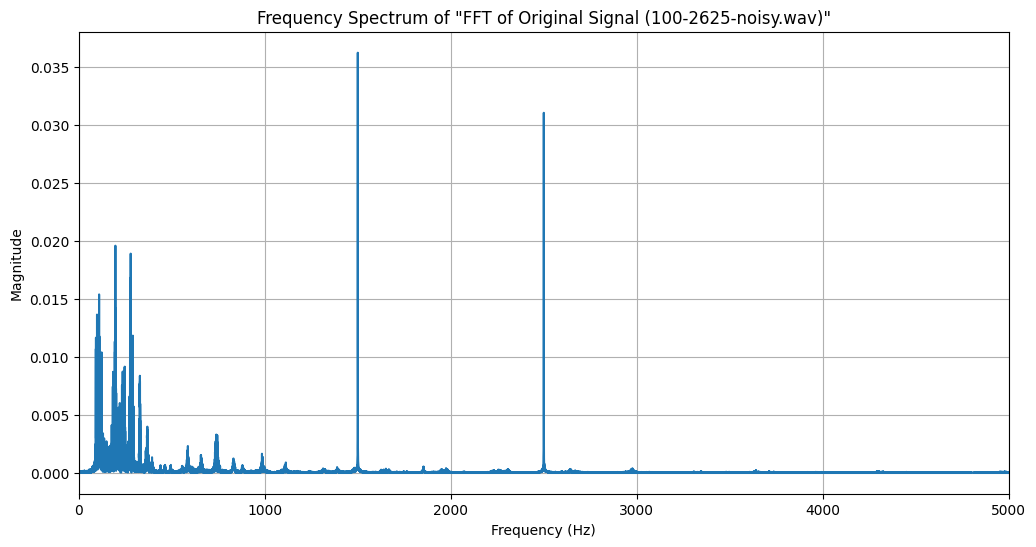

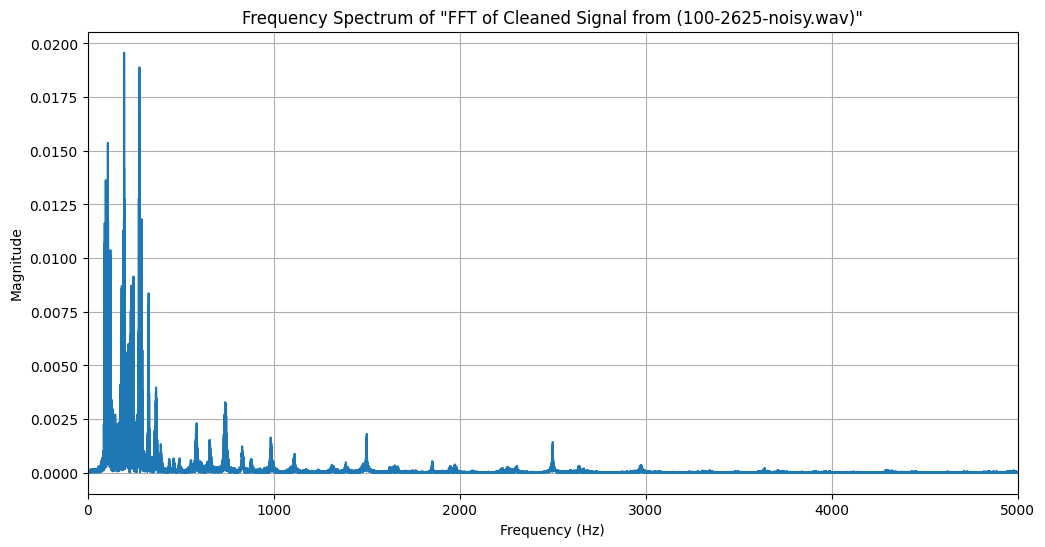

Hidden message: Oignals & Syste	


In [21]:
def process_audio_for_noise_cancellation(filename, 
                                         noise_frequencies_list, 
                                         filter_window_hz=10.0, 
                                         max_freq_display=None):

    # 1. Load and Prepare Audio
    sample_rate, samples, n_samples = load_and_prepare_audio(filename)

    # 2. Plot Original Spectrum
    plot_fft(samples, sample_rate, 
                      f"FFT of Original Signal ({os.path.basename(filename)})", 
                      max_freq_display)

    # 3. Perform FFT Analysis
    original_fft_spectrum, fft_freqs, freq_res = perform_fft_analysis(samples, sample_rate)

    # 4. Interpolate Noise Frequencies
    cleaned_fft_spectrum = interpolate_noise_in_spectrum(original_fft_spectrum, fft_freqs, n_samples,
                                                         noise_frequencies_list, filter_window_hz, freq_res)

    # 5. Perform IFFT
    cleaned_samples_real_time = perform_ifft_and_get_real(cleaned_fft_spectrum)

    # 6. Plot Cleaned Spectrum
    plot_fft(cleaned_samples_real_time, sample_rate, 
                      f"FFT of Cleaned Signal from ({os.path.basename(filename)})", 
                      max_freq_display)

    return sample_rate, cleaned_samples_real_time

returned_sample_rate, returned_cleaned_audio = process_audio_for_noise_cancellation(
    '../inputs/100-2625-noisy.wav',
    [1500.06, 2500.05],
    2,  # Using a very narrow window
    5000.0  # Zoom in on FFT 
)

hidden_message = decode_lsb_from_signal(returned_cleaned_audio)

if hidden_message:
    print("Hidden message:", hidden_message)
else:
    print("No message decoded or an error occurred.")

---

##### Noise Removal in Frequency Spectrum using `lms_adaptive_filter` and `iir_notch` - FAILED!


In [22]:
sample_rate, noisy_signal = wavfile.read("../inputs/100-2625-noisy.wav")

In [23]:
for q in range(20, 81, 5):

    iir_sos = design_iir_notch(sample_rate, 2500.05, q)
    iir_cleaned_code = signal.sosfilt(iir_sos, noisy_signal)

    iir_sos = design_iir_notch(sample_rate, 1500.05, q)
    iir_cleaned_code = signal.sosfilt(iir_sos, iir_cleaned_code)

    print(f"hidden message using iir_notch Q={q}:{decode_lsb_from_signal(iir_cleaned_code)} - FAILED!")

hidden message using iir_notch Q=20:AsN±ÅnF¶6*ðÕ - FAILED!
hidden message using iir_notch Q=25:æÂ»\b4]EúáR - FAILED!
hidden message using iir_notch Q=30:#½`Ï¿³ÉÍhaG« - FAILED!
hidden message using iir_notch Q=35:½¡¡zAPÝÛ^ñAV´ - FAILED!
hidden message using iir_notch Q=40:en£Õ1èë·´°r§ï - FAILED!
hidden message using iir_notch Q=45:­¬þÊ­ë¢H"£¹ - FAILED!
hidden message using iir_notch Q=50:JDµØp$¡±EA - FAILED!
hidden message using iir_notch Q=55:UÔBâ±Ôú¤DÔà - FAILED!
hidden message using iir_notch Q=60:] - FAILED!
hidden message using iir_notch Q=65:ÓÁMFË-¦u±>7J - FAILED!
hidden message using iir_notch Q=70:ÖâàÉÕOóÛÛÎ®oÈ¿ - FAILED!
hidden message using iir_notch Q=75:gîÛ(@¨wðV Õ¢£ - FAILED!
hidden message using iir_notch Q=80:%xùtÓÛv)U[µ( - FAILED!


In [24]:
mu = 0.005 # Step size (learning rate)

sine_ref, cosine_ref = generate_reference_signals(
    len(noisy_signal), sample_rate, 1500.06
)

# Apply adaptive filter
adaptive_cleaned_code, weights_history, final_weights = lms_adaptive_filter(
    noisy_signal, sine_ref, cosine_ref, mu, n_epochs=200
)

sine_ref, cosine_ref = generate_reference_signals(
    len(adaptive_cleaned_code), sample_rate, 2500.05
)

# Apply adaptive filter
adaptive_cleaned_code, weights_history, final_weights = lms_adaptive_filter(
    adaptive_cleaned_code, sine_ref, cosine_ref, mu, n_epochs=200
)

print(f"hidden message using lms_adaptive_filter : {decode_lsb_from_signal(adaptive_cleaned_code)} - FAILED!")

Epoch 1/200 | MSE: 51117463.025244 | Weights: [0.7700, -5.5989]
Epoch 2/200 | MSE: 51104702.857497 | Weights: [1.5381, -11.1838]
Epoch 3/200 | MSE: 51092006.410990 | Weights: [2.3043, -16.7547]
Epoch 4/200 | MSE: 51079373.367518 | Weights: [3.0685, -22.3117]
Epoch 5/200 | MSE: 51066803.410460 | Weights: [3.8309, -27.8548]
Epoch 6/200 | MSE: 51054296.224779 | Weights: [4.5913, -33.3840]
Epoch 7/200 | MSE: 51041851.497008 | Weights: [5.3498, -38.8994]
Epoch 8/200 | MSE: 51029468.915247 | Weights: [6.1065, -44.4010]
Epoch 9/200 | MSE: 51017148.169154 | Weights: [6.8612, -49.8889]
Epoch 10/200 | MSE: 51004888.949936 | Weights: [7.6141, -55.3631]
Epoch 11/200 | MSE: 50992690.950343 | Weights: [8.3651, -60.8235]
Epoch 12/200 | MSE: 50980553.864659 | Weights: [9.1142, -66.2704]
Epoch 13/200 | MSE: 50968477.388693 | Weights: [9.8614, -71.7036]
Epoch 14/200 | MSE: 50956461.219779 | Weights: [10.6068, -77.1232]
Epoch 15/200 | MSE: 50944505.056750 | Weights: [11.3503, -82.5292]
Epoch 16/200 | MSE